# Nhiệm Vụ 3: Câu Đố Kakuro — Thực Nghiệm Bài Toán Thỏa Mãn Ràng Buộc (CSP)

Sổ tay này thực hiện đánh giá định lượng bộ giải Kakuro hướng đối tượng (`source/task3/`) trên **4 bảng câu đố JSON** (gồm bảng mẫu `5×5` 12 biến ở đề bài trang 4 và bảng phức tạp `9×9` 48 biến ở đề bài trang 5) qua **3 cấu hình giải**:
1. **Quay lui cơ bản (`PLAIN_BT`)**: Chọn biến theo thứ tự hàng–cột cố định, giữ nguyên miền `{1..9}`, không tiền xử lý và không lan truyền ràng buộc.
2. **Kiểm tra tiến + MRV (`BT_FC`)**: Tiền xử lý miền bằng danh mục tổ hợp tổng (`SumPartitionCatalog`), chọn biến có miền nhỏ nhất (`MRV`) và loại ứng viên vi phạm ở các ô hàng xóm (`Forward Checking`).
3. **AC-3 mở rộng + MRV/Bậc/LCV (`BT_MAC_HEURISTICS`)**: Kết hợp tiền xử lý tổ hợp tổng, duy trì nhất quán cung mở rộng (`Extended AC-3 / GAC`) trên các dãy `AllDiff + Sum`, chọn biến bằng `MRV + Degree` và sắp xếp giá trị bằng `LCV` 1 bước.

In [1]:
import os
import random
import sys
import tempfile
from pathlib import Path
from threading import Event

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Cau hinh font tieng Viet va do phan giai cho bieu do Matplotlib
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 140

# Dinh vi thu muc ma nguon task3 doc lap voi thu muc lam viec hien tai
cwd = Path.cwd().resolve()
TASK_DIR = next(
    (
        p
        for p in (cwd, cwd / "task3", cwd / "source" / "task3")
        if (p / "csp_model.py").is_file() and (p / "maps").is_dir()
    ),
    None,
)
if TASK_DIR is None:
    raise FileNotFoundError("Khong tim thay thu muc source/task3")
if str(TASK_DIR.parent) not in sys.path:
    sys.path.insert(0, str(TASK_DIR.parent))

from task3 import (
    BoardEditor,
    ExtendedAC3Propagator,
    KakuroCSP,
    KakuroSolver,
    SolverMode,
    SumPartitionCatalog,
)

MAPS_DIR = TASK_DIR / "maps"
FIG_DIR = TASK_DIR.parents[1] / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 3 tại: {TASK_DIR}")

Đã khởi tạo môi trường thực nghiệm Nhiệm vụ 3 tại: D:\3.1. AI\Final\source\task3


## 1. Mô Hình Hóa `<X, D, C>`, Bất Biến Tổng Và Hiệu Quả Thu Hẹp Miền Ban Đầu

Trước khi tìm kiếm quay lui, ta kiểm tra bất biến bảo toàn tổng $\sum \text{Across} = \sum \text{Down}$ của từng bảng và đo mức thu hẹp tổng kích thước miền ứng viên $\sum_{x \in X} |D(x)|$ qua hai tầng tiền xử lý:
- **Tầng 1 (`SumPartitionCatalog`)**: Giao tập chữ số của các tổ hợp tổng hợp lệ giữa dãy ngang và dãy dọc tại từng ô.
- **Tầng 2 (`ExtendedAC3Propagator`)**: Lan truyền ràng buộc nhất quán cung tổng quát (GAC) theo tổ hợp tổng phần dư trên toàn bộ các dãy.

In [2]:
board_files = {
    "Bảng 5×5": "board_5x5_example.json",
    "Bảng 6×6": "board_6x6_medium.json",
    "Bảng 8×8": "board_8x8_hard.json",
    "Bảng 9×9": "board_9x9_complex.json",
}
SumPartitionCatalog.initialize()
boards = {label: KakuroCSP.from_json(MAPS_DIR / name) for label, name in board_files.items()}

pre_rows = []
for label, csp in boards.items():
    sum_h, sum_v = csp.sum_invariants()
    assert sum_h == sum_v, f"Bat bien tong bi vi pham o {label}"

    raw_domain_sum = sum(len(d) for d in csp.initial_domains().values())
    part_domains, _ = SumPartitionCatalog.preprocess_node_domains(csp)
    part_domain_sum = sum(len(d) for d in part_domains.values())

    ac_domains = {p: set(d) for p, d in part_domains.items()}
    ok_ac, _ = ExtendedAC3Propagator.propagate(csp, dict(csp.givens), ac_domains)
    assert ok_ac
    ac_domain_sum = sum(len(d) for d in ac_domains.values())
    singletons = sum(1 for d in ac_domains.values() if len(d) == 1)

    pre_rows.append({
        "Bảng câu đố": label,
        "Kích thước": f"{csp.rows}×{csp.cols}",
        "Số biến |X|": len(csp.variables),
        "Số dãy |C|": len(csp.runs),
        "Tổng H = Tổng V": f"{sum_h} = {sum_v}",
        "Tổng |D| gốc": raw_domain_sum,
        "Sau Tổ hợp tổng": part_domain_sum,
        "Sau AC-3 mở rộng": ac_domain_sum,
        "Ô đơn trị (|D|=1)": f"{singletons}/{len(csp.variables)}",
        "Tỷ lệ thu hẹp (%)": round(100.0 * (raw_domain_sum - ac_domain_sum) / raw_domain_sum, 1),
    })

df_preprocess = pd.DataFrame(pre_rows)
display(df_preprocess)

,Bảng câu đố,Kích thước,Số biến |X|,Số dãy |C|,Tổng H = Tổng V,Tổng |D| gốc,Sau Tổ hợp tổng,Sau AC-3 mở rộng,Ô đơn trị (|D|=1),Tỷ lệ thu hẹp (%)
0,Bảng 5×5,5×5,12,8,60 = 60,108,55,12,12/12,88.9
1,Bảng 6×6,6×6,19,12,106 = 106,171,128,126,0/19,26.3
2,Bảng 8×8,8×8,41,22,248 = 248,369,201,163,4/41,55.8
3,Bảng 9×9,9×9,48,28,249 = 249,432,220,48,48/48,88.9


## 2. Đánh Giá Hiệu Năng 3 Chế Độ Giải Trên 4 Bảng Kakuro (30 Lần Lặp)

Mỗi cặp `(bảng câu đố, chế độ giải)` được chạy làm nóng (`warm-up`) `1` lần để loại nhiễu khởi tạo cache, sau đó đo lặp độc lập **`30` lần** với `record_steps=False` và kiểm chứng 100% nghiệm tìm được bằng `KakuroCSP.verify_solution()`.

In [3]:
modes = [SolverMode.PLAIN_BT, SolverMode.BT_FC, SolverMode.BT_MAC_HEURISTICS]
mode_labels = {
    SolverMode.PLAIN_BT: "Quay lui cơ bản",
    SolverMode.BT_FC: "Kiểm tra tiến + MRV",
    SolverMode.BT_MAC_HEURISTICS: "AC-3 mở rộng + MRV/Bậc/LCV",
}
TRIALS = 30
NODE_LIMIT = 300_000

bench_rows = []
verified_solutions = {}

for label, csp in boards.items():
    for mode in modes:
        # Chay lam nong 1 lan truoc khi bam gio
        KakuroSolver(mode=mode, node_limit=NODE_LIMIT).solve(csp)
        runs = [KakuroSolver(mode=mode, node_limit=NODE_LIMIT).solve(csp) for _ in range(TRIALS)]
        assert all(r.solved and r.valid_verified and csp.verify_solution(r.assignment) for r in runs)

        if mode is SolverMode.BT_MAC_HEURISTICS:
            verified_solutions[label] = runs[0].assignment

        times = np.array([r.elapsed_ms for r in runs], dtype=float)
        bench_rows.append({
            "Bảng": label,
            "Chế độ giải": mode_labels[mode],
            "Số lần đo": TRIALS,
            "Số nút TB": int(round(float(np.mean([r.nodes_explored for r in runs])))),
            "Quay lui TB": int(round(float(np.mean([r.backtracks for r in runs])))),
            "Ứng viên loại TB": int(round(float(np.mean([r.pruned_values for r in runs])))),
            "Thời gian TB (ms)": round(float(times.mean()), 3),
            "Độ lệch chuẩn (ms)": round(float(times.std(ddof=1)), 3),
            "Tỷ lệ đúng (%)": 100.0 * sum(r.valid_verified for r in runs) / TRIALS,
        })

df_bench = pd.DataFrame(bench_rows)
df_csp = df_bench.set_index(["Bảng", "Chế độ giải"])
display(df_csp)

# In tom tat muc giam khong gian tim kiem va danh doi toc do thuc thi
for b_label in ("Bảng 5×5", "Bảng 9×9"):
    sub = df_csp.loc[b_label]
    bt_n = sub.loc["Quay lui cơ bản", "Số nút TB"]
    fc_n = sub.loc["Kiểm tra tiến + MRV", "Số nút TB"]
    mac_n = sub.loc["AC-3 mở rộng + MRV/Bậc/LCV", "Số nút TB"]
    bt_t = sub.loc["Quay lui cơ bản", "Thời gian TB (ms)"]
    fc_t = sub.loc["Kiểm tra tiến + MRV", "Thời gian TB (ms)"]
    mac_t = sub.loc["AC-3 mở rộng + MRV/Bậc/LCV", "Thời gian TB (ms)"]
    print(
        f"[{b_label}] AC-3 mở rộng giảm {bt_n / mac_n:.1f}× số nút ({bt_n:,} -> {mac_n}, 0 quay lui); "
        f"Kiểm tra tiến + MRV đạt thời gian nhanh nhất {bt_t / fc_t:.1f}× "
        f"({bt_t:.2f} ms -> {fc_t:.2f} ms, {fc_n} nút; AC-3: {mac_t:.2f} ms)."
    )

Số lần đo  Số nút TB  Quay lui TB  \
Bảng     Chế độ giải                                                     
Bảng 5×5 Quay lui cơ bản                    30       9933         1097   
         Kiểm tra tiến + MRV                30         13            1   
         AC-3 mở rộng + MRV/Bậc/LCV         30         12            0   
Bảng 6×6 Quay lui cơ bản                    30       6145          671   
         Kiểm tra tiến + MRV                30         19            0   
         AC-3 mở rộng + MRV/Bậc/LCV         30         19            0   
Bảng 8×8 Quay lui cơ bản                    30       8645          933   
         Kiểm tra tiến + MRV                30         63           22   
         AC-3 mở rộng + MRV/Bậc/LCV         30         41            0   
Bảng 9×9 Quay lui cơ bản                    30       9141          988   
         Kiểm tra tiến + MRV                30        100           52   
         AC-3 mở rộng + MRV/Bậc/LCV         30         48            0   

                                     Ứng viên loại TB  Thời gian TB (ms)  \
Bảng     Chế độ giải                                                       
Bảng 5×5 Quay lui cơ bản                            0            119.102   
         Kiểm tra tiến + MRV                       97              1.151   
         AC-3 mở rộng + MRV/Bậc/LCV                96              6.471   
Bảng 6×6 Quay lui cơ bản                            0            117.247   
         Kiểm tra tiến + MRV                      138              2.477   
         AC-3 mở rộng + MRV/Bậc/LCV               137            144.537   
Bảng 8×8 Quay lui cơ bản                            0            135.405   
         Kiểm tra tiến + MRV                      410              5.498   
         AC-3 mở rộng + MRV/Bậc/LCV               321            136.335   
Bảng 9×9 Quay lui cơ bản                            0            169.885   
         Kiểm tra tiến + MRV                      593             29.541   
         AC-3 mở rộng + MRV/Bậc/LCV               384            157.367   

                                     Độ lệch chuẩn (ms)  Tỷ lệ đúng (%)  
Bảng     Chế độ giải                                                     
Bảng 5×5 Quay lui cơ bản                        118.326           100.0  
         Kiểm tra tiến + MRV                      0.494           100.0  
         AC-3 mở rộng + MRV/Bậc/LCV               3.351           100.0  
Bảng 6×6 Quay lui cơ bản                         60.038           100.0  
         Kiểm tra tiến + MRV                      1.319           100.0  
         AC-3 mở rộng + MRV/Bậc/LCV             141.683           100.0  
Bảng 8×8 Quay lui cơ bản                         92.660           100.0  
         Kiểm tra tiến + MRV                      1.157           100.0  
         AC-3 mở rộng + MRV/Bậc/LCV              36.524           100.0  
Bảng 9×9 Quay lui cơ bản                        117.665           100.0  
         Kiểm tra tiến + MRV                     46.567           100.0  
         AC-3 mở rộng + MRV/Bậc/LCV             114.014           100.0

[Bảng 5×5] AC-3 mở rộng giảm 827.8× số nút (9,933 -> 12, 0 quay lui); Kiểm tra tiến + MRV đạt thời gian nhanh nhất 103.5× (119.10 ms -> 1.15 ms, 13 nút; AC-3: 6.47 ms).
[Bảng 9×9] AC-3 mở rộng giảm 190.4× số nút (9,141 -> 48, 0 quay lui); Kiểm tra tiến + MRV đạt thời gian nhanh nhất 5.8× (169.88 ms -> 29.54 ms, 100 nút; AC-3: 157.37 ms).


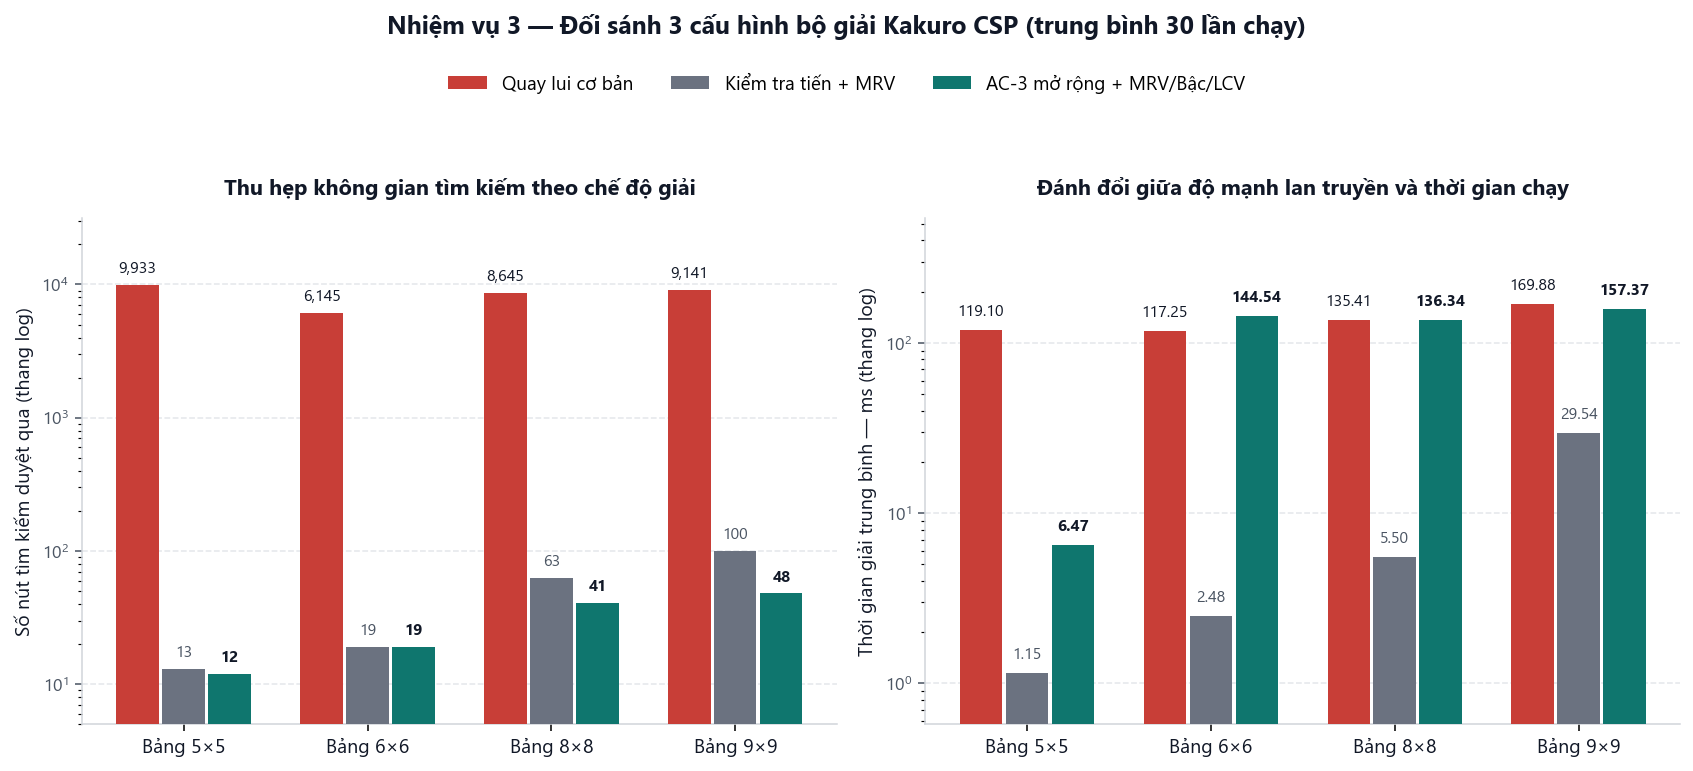

Đã xuất biểu đồ tối giản 3 tông tại: D:\3.1. AI\Final\report\figures\task3_csp_benchmark.png


In [4]:
# Ve bieu do doi sanh 3 tong mau toi gian theo UI.md
COLOR_ALERT = "#C83E37"     # Quay lui co ban (Do gach tram)
COLOR_NEUTRAL = "#6B7280"   # Kiem tra tien + MRV (Xam trung tinh)
COLOR_PRIMARY = "#0F766E"   # AC-3 mo rong + MRV/Bac/LCV (Xanh ngoc tram)
COLOR_GRID = "#E5E7EB"
COLOR_TEXT = "#111827"
COLOR_MUTED = "#4B5563"

board_order = list(board_files.keys())
mode_order = [
    ("Quay lui cơ bản", COLOR_ALERT),
    ("Kiểm tra tiến + MRV", COLOR_NEUTRAL),
    ("AC-3 mở rộng + MRV/Bậc/LCV", COLOR_PRIMARY),
]

x = np.arange(len(board_order))
bar_w = 0.25

fig, (ax_nodes, ax_time) = plt.subplots(1, 2, figsize=(12.2, 5.2), facecolor="white")

for ax, col_name, ylabel, title_txt in (
    (ax_nodes, "Số nút TB", "Số nút tìm kiếm duyệt qua (thang log)", "Thu hẹp không gian tìm kiếm theo chế độ giải"),
    (ax_time, "Thời gian TB (ms)", "Thời gian giải trung bình — ms (thang log)", "Đánh đổi giữa độ mạnh lan truyền và thời gian chạy"),
):
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D1D5DB")
    ax.spines["bottom"].set_color("#D1D5DB")
    ax.grid(axis="y", color=COLOR_GRID, linestyle="--", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

    max_val = 0.0
    min_val = float("inf")
    for idx, (m_label, color) in enumerate(mode_order):
        vals = [float(df_csp.loc[(b, m_label), col_name]) for b in board_order]
        max_val = max(max_val, max(vals))
        min_val = min(min_val, min(vals))
        offset = (idx - 1) * bar_w
        bars = ax.bar(
            x + offset,
            vals,
            width=bar_w * 0.92,
            color=color,
            edgecolor="none",
            label=m_label,
            zorder=3,
        )
        for bar, val in zip(bars, vals):
            lbl = f"{int(round(val)):,}" if col_name == "Số nút TB" else f"{val:.2f}"
            ax.text(
                bar.get_x() + bar.get_width() / 2.0,
                val * 1.15,
                lbl,
                ha="center",
                va="bottom",
                fontsize=8.2,
                fontweight="bold" if idx == 2 else "normal",
                color=COLOR_TEXT if idx != 1 else COLOR_MUTED,
            )

    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(board_order, fontsize=10, color=COLOR_TEXT)
    ax.set_ylabel(ylabel, fontsize=10, color=COLOR_TEXT)
    ax.set_title(title_txt, fontsize=11.2, fontweight="bold", color=COLOR_TEXT, pad=12)
    ax.tick_params(axis="y", labelsize=9, colors=COLOR_MUTED)
    if col_name == "Số nút TB":
        ax.set_ylim(5, max_val * 3.2)
    else:
        ax.set_ylim(max(0.25, min_val * 0.5), max_val * 3.2)

# Dat chu giai chung o dinh bieu do de khong bao gio de len cot du lieu
handles, labels = ax_nodes.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.99),
    ncol=3,
    frameon=False,
    fontsize=9.8,
)
fig.suptitle(
    "Nhiệm vụ 3 — Đối sánh 3 cấu hình bộ giải Kakuro CSP (trung bình 30 lần chạy)",
    fontsize=12.8,
    fontweight="bold",
    color=COLOR_TEXT,
    y=1.05,
)
plt.tight_layout(rect=(0, 0, 1, 0.92))

out_png = FIG_DIR / "task3_csp_benchmark.png"
fig.savefig(out_png, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Đã xuất biểu đồ tối giản 3 tông tại: {out_png}")

## 3. Nghiệm Đã Kiểm Chứng Cho Bảng Mẫu `5×5` Và Bảng Phức Tạp `9×9`

Mọi ô trắng trong lời giải dưới đây đều đã được kiểm chứng độc lập bằng `KakuroCSP.verify_solution()`:
- Chữ số thuộc `{1..9}` và khớp 100% các số cho trước (`givens`);
- Toàn bộ các dãy ngang (`Across`) và dãy dọc (`Down`) thỏa mãn đồng thời điều kiện `AllDiff` và tổng chính xác.

In [5]:
for label in ("Bảng 5×5", "Bảng 9×9"):
    csp = boards[label]
    sol = verified_solutions[label]
    assert csp.verify_solution(sol)
    print(f"=== Lời giải kiểm chứng 100% — {csp.name} ({len(csp.variables)} biến, {len(csp.runs)} dãy) ===")
    print(csp.render_solution_ascii(sol))
    print()

=== Lời giải kiểm chứng 100% — Bảng mẫu 5x5 (Đề bài trang 4) (12 biến, 8 dãy) ===
    #     #   21\   14\     #
    # 14\12     8     4   11\
  \21     9     3     1     8
  \11     5     1     2     3
    #   \16     9     7     #

=== Lời giải kiểm chứng 100% — Bảng phức tạp 9x9 (Đề bài trang 5) (48 biến, 28 dãy) ===
    #     #   44\   16\    9\     #   15\   44\     #
    #   \22     5     9     8  11\3     1     2   14\
    # 17\28     2     7     1     3     4     6     5
  \14     8     6     # 12\20     1     2     8     9
  \17     9     8 29\22     3     2     8     9    7\
    # 12\28     9     8     6     5   \12     7     5
  \14     3     4     5     2    7\  12\6     4     2
  \39     9     3     7     1     6     8     5     #
    #   \16     7     9    \8     1     4     3     #



## 4. Kiểm Thử Tự Động `BoardEditor`, `iter_steps()` Và Các Trường Hợp Biên

Kiểm chứng toàn diện 22 tiêu chí bao phủ: bất biến tổng 4 bảng, tính đúng đắn 3 chế độ, 0 quay lui của `AC-3 mở rộng + MRV/Bậc/LCV`, tính nhất quán của generator `iter_steps()`, nhập nhanh hàng loạt (`bulk_rows`/`apply_bulk_rows`), sinh gợi ý mới có nghiệm (`randomize_clues`), bảng tùy chỉnh `4×4` kèm chữ số cho trước, lưu/mở tệp JSON, phát hiện bảng vô nghiệm (`UNSAT`), dừng theo giới hạn nút (`NODE_LIMIT`), hủy hợp tác qua `cancel_event` (`CANCELLED`), phục hồi sau khi hủy và rút gọn lịch sử `max_recorded_steps`.

In [6]:
checks = []
map_list = list(boards.values())

# 1..4: Bat bien tong tren 4 bang mau
for label, csp in boards.items():
    sh, sv = csp.sum_invariants()
    checks.append((f"Bất biến tổng {label}", sh == sv and sh > 0, f"H={sh}, V={sv}"))

# 5..8: Ca 3 che do giai dung tren ca 4 bang
mac_list, plain_list = [], []
for label, csp in boards.items():
    ok_all = True
    parts = []
    for mode in modes:
        res = KakuroSolver(mode=mode).solve(csp)
        ok_all = ok_all and res.solved and res.valid_verified and res.status == "SOLVED"
        parts.append(f"{mode.name}:{res.nodes_explored}n/{res.backtracks}bt")
        if mode is SolverMode.BT_MAC_HEURISTICS:
            mac_list.append(res)
        if mode is SolverMode.PLAIN_BT:
            plain_list.append(res)
    checks.append((f"3 chế độ giải hợp lệ — {label}", ok_all, ", ".join(parts)))

# 9: 0 quay lui va giam nut so voi Quay lui co ban
checks.append((
    "AC-3 mở rộng + Heuristic đạt 0 quay lui trên 4/4 bảng",
    all(r.backtracks == 0 for r in mac_list) and all(m.nodes_explored < p.nodes_explored for m, p in zip(mac_list, plain_list)),
    f"backtracks={[r.backtracks for r in mac_list]}",
))

# 10: Generator iter_steps() nhat quan voi solve(record_steps=True)
csp_5 = boards["Bảng 5×5"]
streamed = list(KakuroSolver(mode=SolverMode.BT_MAC_HEURISTICS).iter_steps(csp_5))
direct = KakuroSolver(mode=SolverMode.BT_MAC_HEURISTICS, record_steps=True).solve(csp_5)
checks.append((
    "Generator iter_steps() khớp lịch sử và nghiệm",
    len(streamed) == len(direct.steps_trace) and streamed[-1].step_type == "SOLVED" and csp_5.verify_solution(streamed[-1].assignment),
    f"steps={len(streamed)}",
))

# 11..14: BoardEditor bulk round-trip tren ca 4 bang
for label, csp in boards.items():
    ed = BoardEditor(csp)
    txt = ed.bulk_rows()
    ed.apply_bulk_rows(txt)
    rebuilt = ed.validate()
    checks.append((f"BoardEditor nhập nhanh khứ hồi — {label}", rebuilt.raw_grid == csp.raw_grid and rebuilt.givens == csp.givens, f"rows={len(txt)}"))

# 15: randomize_clues() co nghiem tren ca 4 bang
rng = random.Random(42)
rand_ok = True
for csp in map_list:
    ed = BoardEditor(csp)
    ed.randomize_clues(rng=rng)
    res = KakuroSolver(mode=SolverMode.BT_MAC_HEURISTICS).solve(ed.validate())
    rand_ok = rand_ok and res.solved and res.valid_verified
checks.append(("BoardEditor sinh ngẫu nhiên gợi ý có nghiệm 4/4 bảng", rand_ok, "seed=42"))

# 16: Bang tuy chinh 4x4 co chu so cho truoc giai duoc tren 3 che do
ed4 = BoardEditor.new(4)
ed4.set_cell_type((3, 3), white=False)
ed4.randomize_clues(rng=random.Random(7))
ref4 = KakuroSolver(mode=SolverMode.BT_MAC_HEURISTICS).solve(ed4.to_csp())
gpos = sorted(ref4.assignment.keys())[0]
ed4.set_given(gpos, ref4.assignment[gpos])
csp4 = ed4.validate()
checks.append((
    "Bảng tùy chỉnh 4×4 + số cho trước (3 chế độ)",
    all((r := KakuroSolver(mode=m).solve(csp4)).solved and r.valid_verified for m in modes),
    f"given={gpos}:{ref4.assignment[gpos]}",
))

# 17: Luu va mo JSON khu hoi
with tempfile.TemporaryDirectory() as tmpdir:
    tmp_path = Path(tmpdir) / "board_4x4.json"
    ed4.save(tmp_path)
    loaded = BoardEditor.load(tmp_path)
    lres = KakuroSolver(mode=SolverMode.BT_MAC_HEURISTICS).solve(loaded.validate())
    io_ok = loaded.grid == ed4.grid and loaded.givens == ed4.givens and lres.solved and lres.valid_verified
checks.append(("BoardEditor lưu/mở tệp JSON khứ hồi", io_ok, "4×4 kèm số cho trước"))

# 18: Phat hien bang vo nghiem UNSAT tren ca 3 che do
unsat_csp = KakuroCSP("Bang vo nghiem", [["B", {"down": 3}, {"down": 4}], [{"across": 17}, "W", "W"], [{"across": 3}, "W", "W"]])
checks.append((
    "Phát hiện bảng vô nghiệm UNSAT (3 chế độ)",
    all((r := KakuroSolver(mode=m).solve(unsat_csp)).status == "UNSAT" and not r.solved for m in modes),
    "status=UNSAT",
))

# 19: Gioi han node_limit=1
csp_9 = boards["Bảng 9×9"]
lim_res = KakuroSolver(mode=SolverMode.PLAIN_BT, node_limit=1).solve(csp_9)
checks.append(("Dừng đúng hạn với node_limit=1", lim_res.status == "NODE_LIMIT" and not lim_res.solved, f"nodes={lim_res.nodes_explored}"))

# 20: Huy hop tac qua cancel_event
cancel_ev = Event()
cancel_ev.set()
cancel_res = KakuroSolver(mode=SolverMode.BT_MAC_HEURISTICS, cancel_event=cancel_ev).solve(csp_9)
checks.append(("Hủy hợp tác cancel_event -> CANCELLED", cancel_res.status == "CANCELLED" and not cancel_res.solved, f"status={cancel_res.status}"))

# 21: Phuc hoi sau huy hop tac
rec_res = KakuroSolver(mode=SolverMode.BT_MAC_HEURISTICS).solve(csp_9)
checks.append(("Phục hồi giải bảng 9×9 sau khi hủy", rec_res.solved and rec_res.valid_verified, f"nodes={rec_res.nodes_explored}"))

# 22: Rut gon lich su max_recorded_steps giu nguyen buoc SOLVED
trunc_res = KakuroSolver(mode=SolverMode.BT_MAC_HEURISTICS, record_steps=True, max_recorded_steps=15).solve(csp_9)
checks.append((
    "Rút gọn lịch sử max_recorded_steps=15 giữ bước SOLVED",
    trunc_res.solved and trunc_res.trace_truncated and len(trunc_res.steps_trace) == 15 and trunc_res.steps_trace[-1].step_type == "SOLVED",
    f"len={len(trunc_res.steps_trace)}, truncated={trunc_res.trace_truncated}",
))

df_checks = pd.DataFrame([
    {"STT": i, "Tiêu chí kiểm thử": title, "Kết quả": "Đạt" if ok else "Không đạt", "Chi tiết": detail}
    for i, (title, ok, detail) in enumerate(checks, start=1)
])
assert all(ok for _, ok, _ in checks), "Ton tai kiem thu khong dat!"
display(df_checks)
print(f"Hoàn tất kiểm chứng: {len(checks)}/{len(checks)} tiêu chí đạt 100%.")

,STT,Tiêu chí kiểm thử,Kết quả,Chi tiết
0,1,Bất biến tổng Bảng 5×5,Đạt,"H=60, V=60"
1,2,Bất biến tổng Bảng 6×6,Đạt,"H=106, V=106"
2,3,Bất biến tổng Bảng 8×8,Đạt,"H=248, V=248"
3,4,Bất biến tổng Bảng 9×9,Đạt,"H=249, V=249"
4,5,3 chế độ giải hợp lệ — Bảng 5×5,Đạt,"PLAIN_BT:9933n/1097bt, BT_FC:13n/1bt, BT_MAC_H..."
5,6,3 chế độ giải hợp lệ — Bảng 6×6,Đạt,"PLAIN_BT:6145n/671bt, BT_FC:19n/0bt, BT_MAC_HE..."
6,7,3 chế độ giải hợp lệ — Bảng 8×8,Đạt,"PLAIN_BT:8645n/933bt, BT_FC:63n/22bt, BT_MAC_H..."
7,8,3 chế độ giải hợp lệ — Bảng 9×9,Đạt,"PLAIN_BT:9141n/988bt, BT_FC:100n/52bt, BT_MAC_..."
8,9,AC-3 mở rộng + Heuristic đạt 0 quay lui trên 4...,Đạt,"backtracks=[0, 0, 0, 0]"
9,10,Generator iter_steps() khớp lịch sử và nghiệm,Đạt,steps=27


Hoàn tất kiểm chứng: 22/22 tiêu chí đạt 100%.
